Learning Rate Scheduling and Early Stopping

In this notebook, I will compare a regular training run with a run that uses a learning-rate scheduler and early stopping. I will keep the model, data split, and training transforms the same so the comparison is easier to interpret.

The purpose is to learn how these training techniques work. They do not guarantee a higher score in every run.

Imports and setup

In [18]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

BATCH_SIZE = 128
MAX_EPOCHS = 10
PATIENCE = 3
NUM_WORKERS = 2

Device: cuda


Load CIFAR-10

In [19]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_full = datasets.CIFAR10(root="data", train=True, download=True, transform=train_transform)
eval_full = datasets.CIFAR10(root="data", train=True, download=True, transform=eval_transform)
test_data = datasets.CIFAR10(root="data", train=False, download=True, transform=eval_transform)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_full), generator=generator).tolist()
train_indices, val_indices = indices[:45000], indices[45000:]

train_data = Subset(train_full, train_indices)
val_data = Subset(eval_full, val_indices)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available()
}
train_loader = DataLoader(train_data, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_data, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_data, shuffle=False, **loader_kwargs)

print(f"Train: {len(train_data)} | Validation: {len(val_data)} | Test: {len(test_data)}")

Train: 45000 | Validation: 5000 | Test: 10000


Define the CNN

In [20]:
class CIFAR10CNN(nn.Module):
    def __init__(self, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

criterion = nn.CrossEntropyLoss()

Training and evaluation function

In [21]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

Experiment A: fixed learning rate

In [22]:
fixed_model = CIFAR10CNN().to(device)
fixed_optimizer = torch.optim.Adam(fixed_model.parameters(), lr=0.001)

fixed_history = {"epoch": [], "train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc = run_epoch(fixed_model, train_loader, fixed_optimizer)
    val_loss, val_acc = run_epoch(fixed_model, val_loader)

    fixed_history["epoch"].append(epoch)
    fixed_history["train_loss"].append(train_loss)
    fixed_history["train_accuracy"].append(train_acc)
    fixed_history["val_loss"].append(val_loss)
    fixed_history["val_accuracy"].append(val_acc)

    print(f"Fixed LR | Epoch {epoch:02d} | train acc {train_acc:.2%} | val acc {val_acc:.2%} | val loss {val_loss:.4f}")

Fixed LR | Epoch 01 | train acc 35.69% | val acc 47.94% | val loss 1.4477
Fixed LR | Epoch 02 | train acc 49.02% | val acc 57.90% | val loss 1.1631
Fixed LR | Epoch 03 | train acc 55.92% | val acc 62.06% | val loss 1.0455
Fixed LR | Epoch 04 | train acc 60.36% | val acc 67.26% | val loss 0.9057
Fixed LR | Epoch 05 | train acc 63.39% | val acc 68.84% | val loss 0.8753
Fixed LR | Epoch 06 | train acc 65.56% | val acc 71.06% | val loss 0.8002
Fixed LR | Epoch 07 | train acc 67.20% | val acc 71.64% | val loss 0.7911
Fixed LR | Epoch 08 | train acc 69.17% | val acc 73.26% | val loss 0.7467
Fixed LR | Epoch 09 | train acc 69.84% | val acc 73.82% | val loss 0.7423
Fixed LR | Epoch 10 | train acc 70.93% | val acc 73.78% | val loss 0.7236


Experiment B: learning-rate scheduler and early stopping

In [23]:
scheduled_model = CIFAR10CNN().to(device)
scheduled_optimizer = torch.optim.Adam(scheduled_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    scheduled_optimizer, mode="min", factor=0.5, patience=1
)

scheduled_history = {"epoch": [], "train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": [], "lr": []}
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc = run_epoch(scheduled_model, train_loader, scheduled_optimizer)
    val_loss, val_acc = run_epoch(scheduled_model, val_loader)
    scheduler.step(val_loss)

    current_lr = scheduled_optimizer.param_groups[0]["lr"]
    scheduled_history["epoch"].append(epoch)
    scheduled_history["train_loss"].append(train_loss)
    scheduled_history["train_accuracy"].append(train_acc)
    scheduled_history["val_loss"].append(val_loss)
    scheduled_history["val_accuracy"].append(val_acc)
    scheduled_history["lr"].append(current_lr)

    print(f"Scheduled | Epoch {epoch:02d} | train acc {train_acc:.2%} | val acc {val_acc:.2%} | val loss {val_loss:.4f} | lr {current_lr:g}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {key: value.detach().cpu().clone() for key, value in scheduled_model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}; validation loss did not improve for {PATIENCE} epochs.")
        break

if best_state is not None:
    scheduled_model.load_state_dict(best_state)
    print("Restored model weights from the epoch with the lowest validation loss.")

Scheduled | Epoch 01 | train acc 36.16% | val acc 48.46% | val loss 1.4002 | lr 0.001
Scheduled | Epoch 02 | train acc 49.57% | val acc 56.44% | val loss 1.1917 | lr 0.001
Scheduled | Epoch 03 | train acc 56.36% | val acc 62.84% | val loss 1.0287 | lr 0.001
Scheduled | Epoch 04 | train acc 60.88% | val acc 67.10% | val loss 0.9138 | lr 0.001
Scheduled | Epoch 05 | train acc 63.33% | val acc 69.94% | val loss 0.8481 | lr 0.001
Scheduled | Epoch 06 | train acc 66.12% | val acc 69.50% | val loss 0.8535 | lr 0.001
Scheduled | Epoch 07 | train acc 67.97% | val acc 73.22% | val loss 0.7581 | lr 0.001
Scheduled | Epoch 08 | train acc 69.60% | val acc 73.74% | val loss 0.7510 | lr 0.001
Scheduled | Epoch 09 | train acc 70.84% | val acc 73.66% | val loss 0.7317 | lr 0.001
Scheduled | Epoch 10 | train acc 71.36% | val acc 76.14% | val loss 0.6865 | lr 0.001
Restored model weights from the epoch with the lowest validation loss.


Compare the learning curves

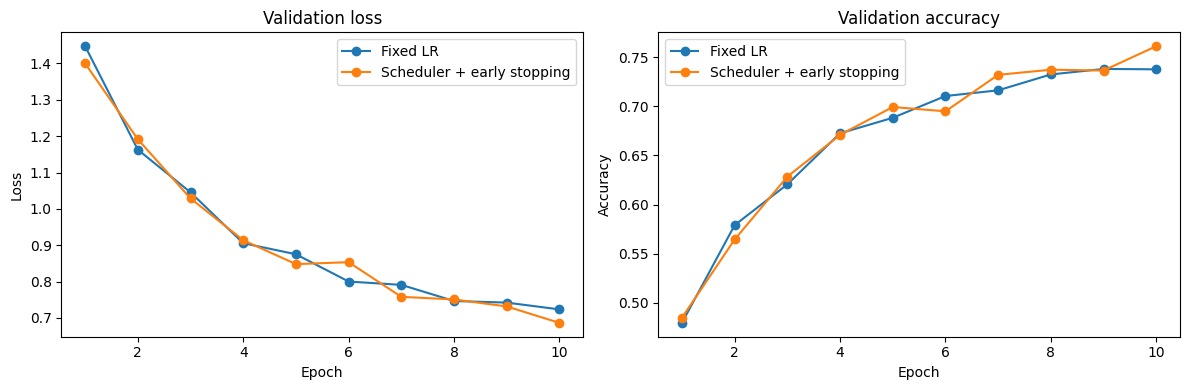

Learning rates used in scheduled run: [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001]


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fixed_history["epoch"], fixed_history["val_loss"], marker="o", label="Fixed LR")
axes[0].plot(scheduled_history["epoch"], scheduled_history["val_loss"], marker="o", label="Scheduler + early stopping")
axes[0].set_title("Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(fixed_history["epoch"], fixed_history["val_accuracy"], marker="o", label="Fixed LR")
axes[1].plot(scheduled_history["epoch"], scheduled_history["val_accuracy"], marker="o", label="Scheduler + early stopping")
axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Learning rates used in scheduled run:", scheduled_history["lr"])

Final test evaluation

In [25]:
test_loss, test_accuracy = run_epoch(scheduled_model, test_loader)
print(f"Scheduled model test loss: {test_loss:.4f}")
print(f"Scheduled model test accuracy: {test_accuracy:.2%}")

Scheduled model test loss: 0.7133
Scheduled model test accuracy: 75.28%
